In [1]:
import json
import pickle
from datetime import datetime
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, accuracy_score,
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Intentar cargar HFDatasetLoader de la carpeta src del profesor o fallback directo
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
try:
    from clases_po import HFDatasetLoader
except ImportError:
    from datasets import load_dataset
    class HFDatasetLoader:
        def _init_(self, dataset_name, split="train", filename=None):
            self.dataset_name = dataset_name
            self.split = split
            self.filename = Path(filename) if filename else None
        def load(self):
            if self.filename and self.filename.exists():
                return pd.read_csv(self.filename)
            ds = load_dataset(self.dataset_name, split=self.split)
            df = ds.to_pandas()
            if self.filename:
                self.filename.parent.mkdir(parents=True, exist_ok=True)
                df.to_csv(self.filename, index=False)
            return df

OBJETIVO = "Churn"
COLORES = {"se_queda": "#1f6fe5", "abandona": "#e5384b", "naranja": "#f2661b", "verde": "#10a179", "morado": "#8a3ff0"}
SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)

/workspaces/Machinelearning_iudigitall/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Carga automática desde Hugging Face Datasets
loader = HFDatasetLoader(
    dataset_name="scikit-learn/churn-prediction",
    split="train",
    filename="datos/telco_churn.csv"
)
df_crudo = loader.load()

print("Forma (filas, columnas):", df_crudo.shape)
df_crudo.head()

Generating train split: 100%|█████████████████████| 7043/7043 [00:00<00:00, 35776.29 examples/s]

Forma (filas, columnas): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
diccionario = pd.DataFrame([
    ("customerID", "identificador único del cliente", "no se usa para entrenar"),
    ("gender", "género del cliente (Female, Male)", "¿quién es? (variable sensible)"),
    ("SeniorCitizen", "adulto mayor (1 = sí, 0 = no)", "¿quién es?"),
    ("Partner", "tiene pareja (Yes, No)", "¿quién es?"),
    ("Dependents", "tiene dependientes (Yes, No)", "¿quién es?"),
    ("tenure", "meses de antigüedad con la empresa", "¿qué tan leal ha sido?"),
    ("PhoneService", "servicio de telefonía (Yes, No)", "¿qué servicios tiene?"),
    ("MultipleLines", "múltiples líneas telefónicas", "¿qué servicios tiene?"),
    ("InternetService", "proveedor de internet (DSL, Fiber optic, No)", "¿qué tecnología usa?"),
    ("OnlineSecurity", "servicio de seguridad en línea", "¿tiene protección extra?"),
    ("Contract", "tipo de contrato (Month-to-month, One year, Two year)", "¿qué compromiso tiene?"),
    ("MonthlyCharges", "monto facturado mensual en dólares", "¿cuánto paga cada mes?"),
    ("TotalCharges", "monto histórico total facturado", "¿cuánto ha aportado en total?"),
    (OBJETIVO, "1 = abandonó el servicio (Yes), 0 = continúa (No)", "la respuesta: y"),
], columns=["columna", "significado", "pregunta del negocio"])
diccionario

,columna,significado,pregunta del negocio
0,customerID,identificador único del cliente,no se usa para entrenar
1,gender,"género del cliente (Female, Male)",¿quién es? (variable sensible)
2,SeniorCitizen,"adulto mayor (1 = sí, 0 = no)",¿quién es?
3,Partner,"tiene pareja (Yes, No)",¿quién es?
4,Dependents,"tiene dependientes (Yes, No)",¿quién es?
5,tenure,meses de antigüedad con la empresa,¿qué tan leal ha sido?
6,PhoneService,"servicio de telefonía (Yes, No)",¿qué servicios tiene?
7,MultipleLines,múltiples líneas telefónicas,¿qué servicios tiene?
8,InternetService,"proveedor de internet (DSL, Fiber optic, No)",¿qué tecnología usa?
9,OnlineSecurity,servicio de seguridad en línea,¿tiene protección extra?


In [4]:
df = df_crudo.copy()
n = len(df)
sin_id = df.drop(columns=["customerID"], errors="ignore")

# TotalCharges viene como texto con posibles espacios en blanco en cuentas nuevas (tenure = 0)
total_charges_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
nulos_total_charges = int(total_charges_num.isna().sum())

calidad = pd.DataFrame([
    ("Completitud · TotalCharges nulos o blancos", nulos_total_charges, "imputar con 0.0 (clientes nuevos)"),
    ("Unicidad · filas duplicadas (sin customerID)", int(sin_id.duplicated().sum()), "eliminar si existen"),
    ("Dominio · Churn valores válidos", int((~df["Churn"].isin(["Yes", "No", 1, 0])).sum()), "verificar consistencia"),
], columns=["validación", "resultado", "decisión"])
calidad["métrica (%)"] = (calidad["resultado"] / n * 100).round(2)
calidad

/tmp/ipykernel_7258/1788004393.py:14: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  calidad["métrica (%)"] = (calidad["resultado"] / n * 100).round(2)


,validación,resultado,decisión,métrica (%)
0,Completitud · TotalCharges nulos o blancos,11,imputar con 0.0 (clientes nuevos),0.16
1,Unicidad · filas duplicadas (sin customerID),22,eliminar si existen,0.31
2,Dominio · Churn valores válidos,0,verificar consistencia,0.00


In [5]:
# Aplicar reglas de limpieza y codificación
registro = [("datos crudos", len(df))]

df = df.loc[~df.drop(columns=["customerID"], errors="ignore").duplicated()].copy()
registro.append(("sin duplicados", len(df)))

# Corrección de tipo e imputación de TotalCharges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

# Mapeo de la variable objetivo binaria: Yes -> 1 (abandona), No -> 0 (se queda)
if df[OBJETIVO].dtype == "object":
    df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0})

registro.append(("TotalCharges saneado y Churn binario", len(df)))
pd.DataFrame(registro, columns=["paso", "filas"])

/tmp/ipykernel_7258/1886798542.py:8: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
/tmp/ipykernel_7258/1886798542.py:12: FutureWarning: ChainedAssignmentErro

,paso,filas
0,datos crudos,7043
1,sin duplicados,7021
2,TotalCharges saneado y Churn binario,7021


In [6]:
# Descripción de variables numéricas y cálculo del riesgo base
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(1))

tasa = df[OBJETIVO].mean()
print(f"\nTasa de deserción base (Churn): {df[OBJETIVO].sum():,} de {len(df):,} = {tasa:.1%}")
print(f"Un modelo perezoso que siempre diga «se queda» acertaría el {1 - tasa:.1%}")

       tenure  MonthlyCharges  TotalCharges
count  7021.0          7021.0        7021.0
mean     32.5            64.9        2286.8
std      24.5            30.1        2266.9
min       0.0            18.2           0.0
25%       9.0            35.8         403.4
50%      29.0            70.4        1400.6
75%      55.0            89.9        3801.7
max      72.0           118.8        8684.8

Tasa de deserción base (Churn): 1,857 de 7,021 = 26.4%
Un modelo perezoso que siempre diga «se queda» acertaría el 73.6%


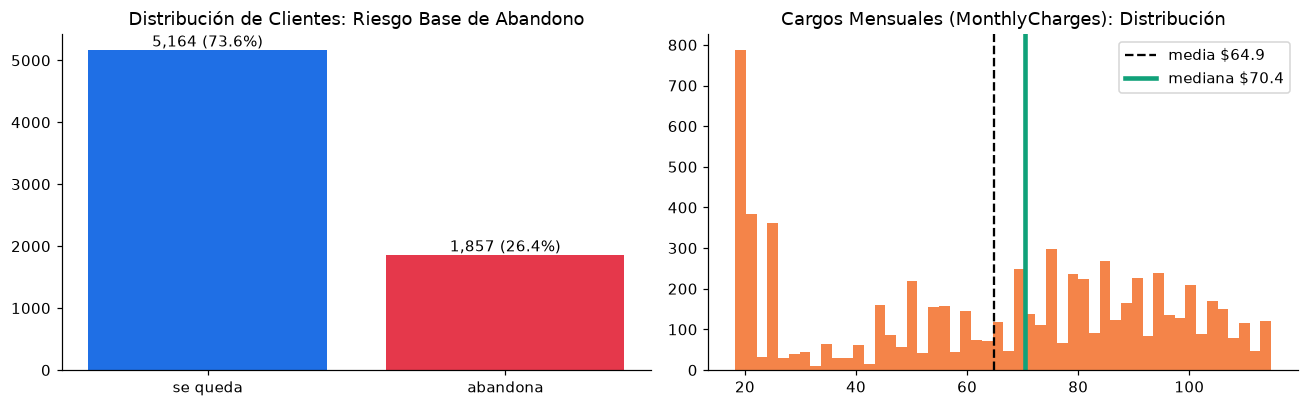

In [7]:
# Gráficos de exploración del negocio
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
conteo = df[OBJETIVO].map({0: "se queda", 1: "abandona"}).value_counts()
barras = ejes[0].bar(conteo.index, conteo.values, color=[COLORES["se_queda"], COLORES["abandona"]])
ejes[0].bar_label(barras, labels=[f"{v:,} ({v / len(df):.1%})" for v in conteo.values])
ejes[0].set_title("Distribución de Clientes: Riesgo Base de Abandono")

tope = df["MonthlyCharges"].quantile(0.99)
ejes[1].hist(df["MonthlyCharges"].clip(upper=tope), bins=50, color=COLORES["naranja"], alpha=.8)
ejes[1].axvline(df["MonthlyCharges"].mean(), color="black", ls="--", label=f"media ${df['MonthlyCharges'].mean():,.1f}")
ejes[1].axvline(df["MonthlyCharges"].median(), color=COLORES["verde"], lw=3, label=f"mediana ${df['MonthlyCharges'].median():,.1f}")
ejes[1].set_title("Cargos Mensuales (MonthlyCharges): Distribución")
ejes[1].legend()
plt.tight_layout()
plt.show()

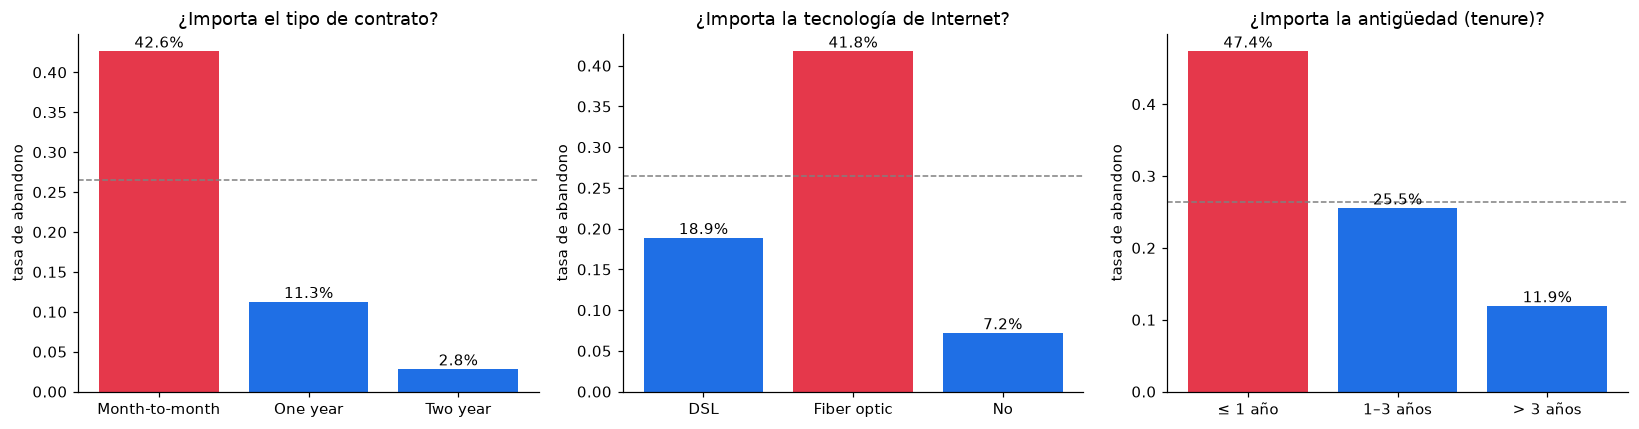

Línea gris: riesgo base de abandono (26.5%). Contratos mes a mes e internet por fibra presentan mayor riesgo.


In [8]:
# Hipótesis del negocio: ¿Qué factores disparan la fuga?
grupos = {
    "¿Importa el tipo de contrato?": df["Contract"],
    "¿Importa la tecnología de Internet?": df["InternetService"],
    "¿Importa la antigüedad (tenure)?": pd.cut(df["tenure"], [-np.inf, 12, 36, np.inf], labels=["≤ 1 año", "1–3 años", "> 3 años"])
}

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (titulo, grupo) in zip(ejes, grupos.items()):
    t = df.groupby(grupo, observed=True)[OBJETIVO].mean()
    barras = eje.bar(t.index.astype(str), t.values, color=[COLORES["abandona"] if v > tasa else COLORES["se_queda"] for v in t.values])
    eje.bar_label(barras, labels=[f"{v:.1%}" for v in t.values])
    eje.axhline(tasa, color="gray", ls="--", lw=1)
    eje.set_title(titulo)
    eje.set_ylabel("tasa de abandono")
plt.tight_layout()
plt.show()
print("Línea gris: riesgo base de abandono (26.5%). Contratos mes a mes e internet por fibra presentan mayor riesgo.")

In [9]:
# Variables sensibles: Género
print("Tasa de deserción por género:")
print(df.groupby("gender")[OBJETIVO].mean().round(3))

Tasa de deserción por género:
gender
Female    0.268
Male      0.261
Name: Churn, dtype: float64


In [13]:
# Separación en entrenamiento (80%) y prueba (20%) estratificado
columnas_excluidas = ["customerID", OBJETIVO]
X_raw = df.drop(columns=columnas_excluidas, errors="ignore")

# Se especifica dtype=float para evitar columnas booleanas que causen error en NumPy
X = pd.get_dummies(X_raw, drop_first=True, dtype=float)
y = df[OBJETIVO]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.DataFrame({"clientes": [len(y_tr), len(y_te)],
              "tasa de abandono": [f"{y_tr.mean():.2%}", f"{y_te.mean():.2%}"]},
             index=["entrenamiento", "prueba"])

,clientes,tasa de abandono
entrenamiento,5616,26.44%
prueba,1405,26.48%


In [14]:
# Cómo elige sus preguntas el árbol: Gini y Ganancia (cálculo paso a paso)
def gini(etiquetas):
    p = np.bincount(etiquetas, minlength=2) / len(etiquetas)
    return 1 - np.sum(p ** 2)

def evaluar_corte(x, etiquetas, umbral):
    izq, der = etiquetas[x <= umbral], etiquetas[x > umbral]
    if len(izq) == 0 or len(der) == 0:
        return gini(etiquetas), 0.0
    g_corte = len(izq) / len(etiquetas) * gini(izq) + len(der) / len(etiquetas) * gini(der)
    return g_corte, gini(etiquetas) - g_corte

y_arr = y_tr.to_numpy()
print(f"Gini de la raíz: {gini(y_arr):.3f}")

mejores = []
for col in X_tr.columns:
    # Conversión explícita a float para compatibilidad total con NumPy
    x = X_tr[col].astype(float).to_numpy()
    valores_unicos = np.unique(x)
    
    # Si la variable es binaria (0 y 1), el corte natural es 0.5; si es continua, usamos quantiles
    if len(valores_unicos) <= 2:
        umbrales = np.array([0.5])
    else:
        candidatos = np.unique(np.quantile(x, np.linspace(0, 1, 21)))
        umbrales = (candidatos[:-1] + candidatos[1:]) / 2
        
    if len(umbrales) == 0:
        continue
        
    res = [evaluar_corte(x, y_arr, u) for u in umbrales]
    k = int(np.argmax([r[1] for r in res]))
    mejores.append({"variable": col, "umbral": umbrales[k], "ganancia": res[k][1]})

print("\nVariables con mayor ganancia de información en la raíz:")
pd.DataFrame(mejores).sort_values("ganancia", ascending=False).head(8).round(4)

Gini de la raíz: 0.389

Variables con mayor ganancia de información en la raíz:


,variable,umbral,ganancia
1,tenure,18.0,0.0398
10,InternetService_Fiber optic,0.5,0.0396
28,PaymentMethod_Electronic check,0.5,0.0361
25,Contract_Two year,0.5,0.0351
11,InternetService_No,0.5,0.0214
12,OnlineSecurity_No internet service,0.5,0.0214
16,DeviceProtection_No internet service,0.5,0.0214
18,TechSupport_No internet service,0.5,0.0214


In [15]:
# Selección de hiperparámetro max_depth con Validación Cruzada (StratifiedKFold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for prof in [1, 2, 3, 4, 5, 6, 8, 12, None]:
    r = cross_validate(DecisionTreeClassifier(max_depth=prof, random_state=SEMILLA), X_tr, y_tr,
                       cv=cv, scoring="roc_auc", return_train_score=True)
    filas.append({"max_depth": "sin límite" if prof is None else prof,
                  "AUC entrenamiento": r["train_score"].mean(), "AUC validación": r["test_score"].mean(),
                  "desviación": r["test_score"].std()})
validacion = pd.DataFrame(filas)
validacion["brecha"] = validacion["AUC entrenamiento"] - validacion["AUC validación"]
validacion.round(3)

/tmp/ipykernel_7258/202545197.py:11: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  validacion["brecha"] = validacion["AUC entrenamiento"] - validacion["AUC validación"]


,max_depth,AUC entrenamiento,AUC validación,desviación,brecha
0,1,0.680,0.672,0.018,0.008
1,2,0.771,0.771,0.018,0.000
2,3,0.814,0.810,0.022,0.004
3,4,0.836,0.823,0.017,0.013
4,5,0.852,0.824,0.021,0.028
5,6,0.868,0.815,0.017,0.053
6,8,0.909,0.777,0.029,0.132
7,12,0.983,0.688,0.027,0.294
8,sin límite,1.000,0.646,0.017,0.354


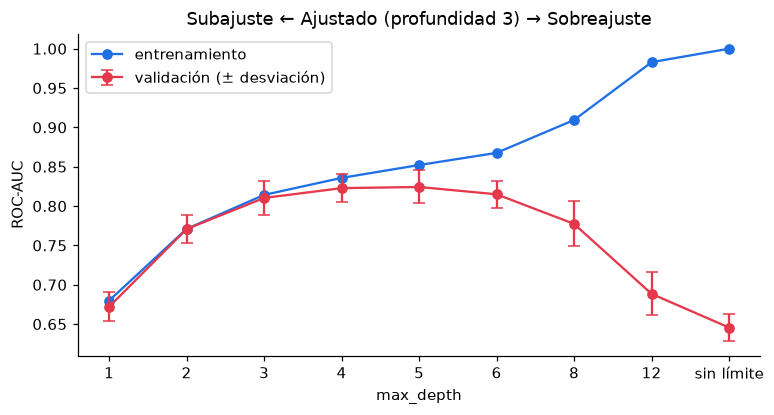

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
etiquetas = validacion["max_depth"].astype(str)
ax.plot(etiquetas, validacion["AUC entrenamiento"], "o-", color=COLORES["se_queda"], label="entrenamiento")
ax.errorbar(etiquetas, validacion["AUC validación"], yerr=validacion["desviación"], fmt="o-",
            color=COLORES["abandona"], capsize=4, label="validación (± desviación)")
ax.set_xlabel("max_depth")
ax.set_ylabel("ROC-AUC")
ax.set_title("Subajuste ← Ajustado (profundidad 3) → Sobreajuste")
ax.legend()
plt.show()

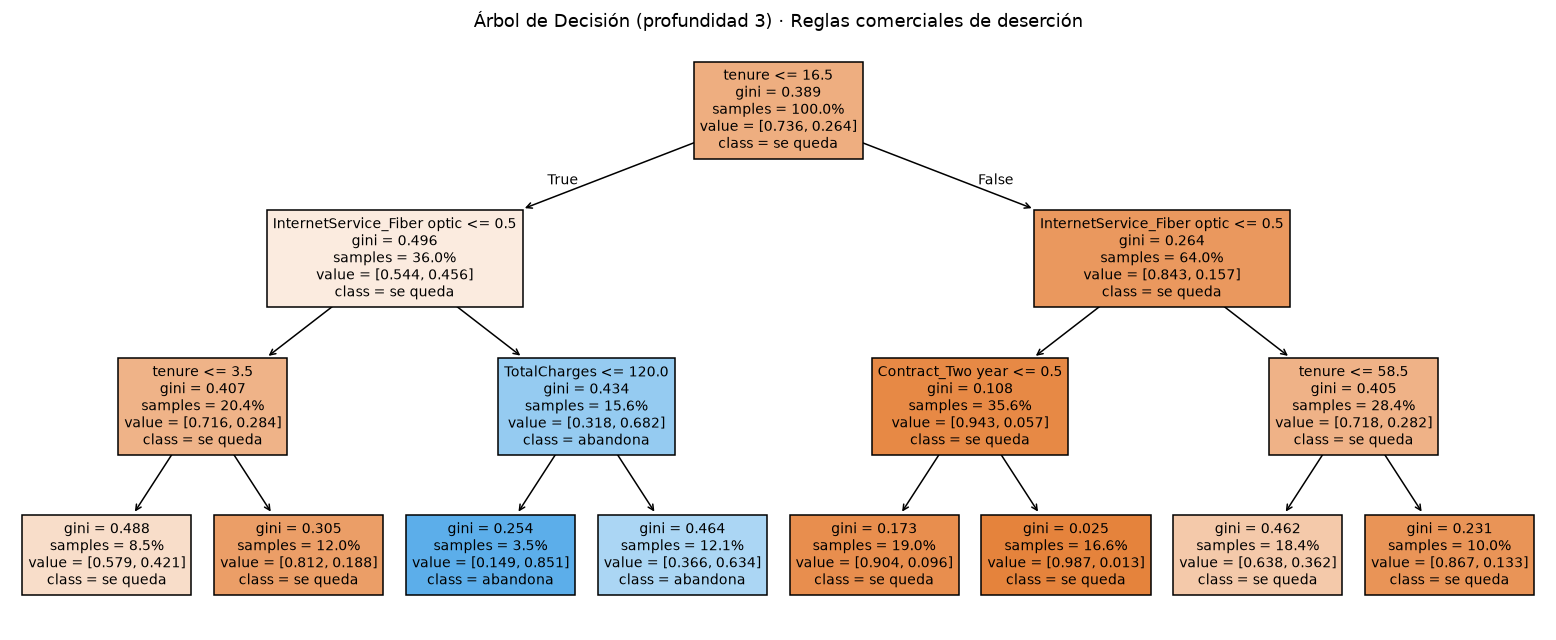

In [17]:
# Entrenar el árbol óptimo elegido (max_depth = 3) y visualizar sus reglas
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(X_tr, y_tr)

plt.figure(figsize=(18, 7))
plot_tree(arbol, feature_names=X.columns, class_names=["se queda", "abandona"], filled=True,
          proportion=True, impurity=True, fontsize=9)
plt.title("Árbol de Decisión (profundidad 3) · Reglas comerciales de deserción")
plt.show()

In [18]:
pred = arbol.predict(X_te)
proba = arbol.predict_proba(X_te)[:, 1]
perezoso = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)

print(f"Exactitud del Árbol de Decisión:          {accuracy_score(y_te, pred):.1%}")
print(f"Exactitud de responder siempre 'se queda': {accuracy_score(y_te, perezoso.predict(X_te)):.1%}")

Exactitud del Árbol de Decisión:          78.4%
Exactitud de responder siempre 'se queda': 73.5%


Leales confirmados (VN):               963 · Falsas alarmas de fuga (FP): 70
Fugas no detectadas (FN, pérdida):      234 · Fugas detectadas a tiempo (VP): 138

Recall (sensibilidad) = 138 / (138 + 234) = 37.1%
Precisión             = 138 / (138 + 70) = 66.3%


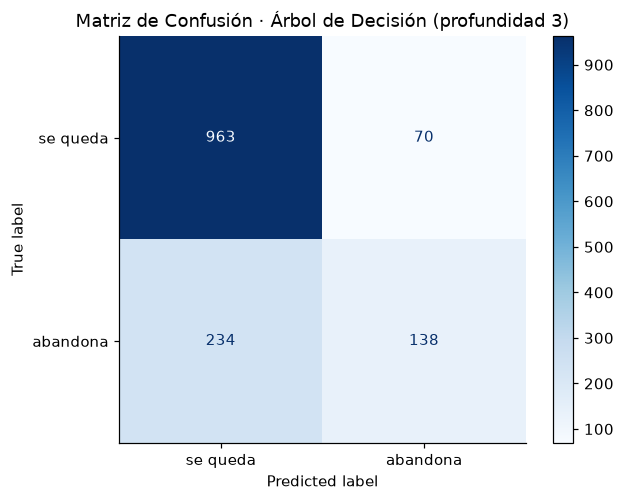

              precision    recall  f1-score   support

    se queda      0.805     0.932     0.864      1033
    abandona      0.663     0.371     0.476       372

    accuracy                          0.784      1405
   macro avg      0.734     0.652     0.670      1405
weighted avg      0.767     0.784     0.761      1405



In [19]:
vn, fp, fn, vp = confusion_matrix(y_te, pred).ravel()
print(f"Leales confirmados (VN):               {vn:,} · Falsas alarmas de fuga (FP): {fp:,}")
print(f"Fugas no detectadas (FN, pérdida):      {fn:,} · Fugas detectadas a tiempo (VP): {vp:,}")
print(f"\nRecall (sensibilidad) = {vp} / ({vp} + {fn}) = {vp / (vp + fn):.1%}")
print(f"Precisión             = {vp} / ({vp} + {fp}) = {vp / (vp + fp):.1%}")

ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["se queda", "abandona"],
                                        cmap="Blues", values_format=",d")
plt.title("Matriz de Confusión · Árbol de Decisión (profundidad 3)")
plt.show()

print(classification_report(y_te, pred, target_names=["se queda", "abandona"], digits=3))

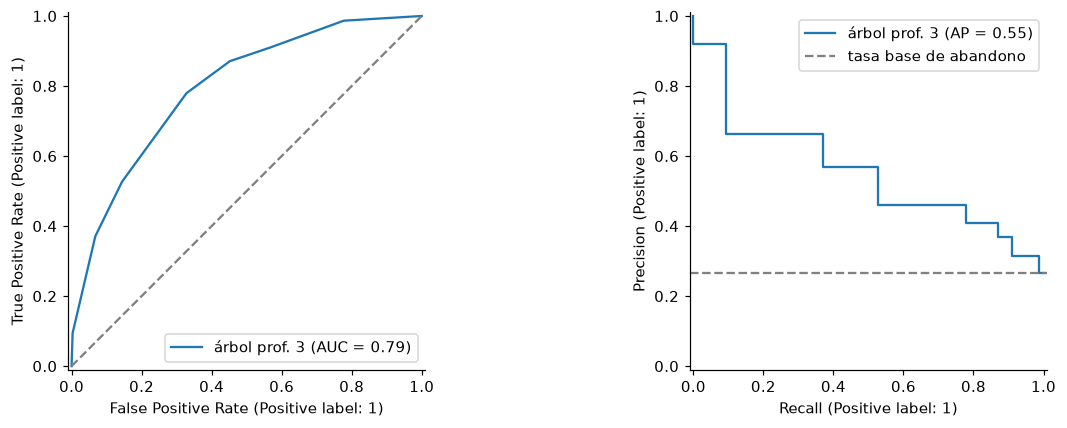

ROC-AUC: 0.795 · PR-AUC: 0.555 (tasa base 0.265)


In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_te, proba, ax=ejes[0], name="árbol prof. 3")
ejes[0].plot([0, 1], [0, 1], "--", color="gray")
PrecisionRecallDisplay.from_predictions(y_te, proba, ax=ejes[1], name="árbol prof. 3")
ejes[1].axhline(y_te.mean(), ls="--", color="gray", label="tasa base de abandono")
ejes[1].legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc_score(y_te, proba):.3f} · PR-AUC: {average_precision_score(y_te, proba):.3f} (tasa base {y_te.mean():.3f})")

                                          hojas  exactitud prueba  recall  \
escenario                                                                   
1 · sin límite (sobreajustado)             1139             0.722   0.497   
2 · profundidad 2 (subajustado)               4             0.784   0.371   
3 · profundidad 3 (óptimo)                    8             0.784   0.371   
4 · prof. 3 balanceado (prioriza recall)      8             0.653   0.887   

                                          precisión     F1  ROC-AUC  \
escenario                                                             
1 · sin límite (sobreajustado)                0.477  0.487    0.650   
2 · profundidad 2 (subajustado)               0.663  0.476    0.754   
3 · profundidad 3 (óptimo)                    0.663  0.476    0.795   
4 · prof. 3 balanceado (prioriza recall)      0.426  0.575    0.791   

                                          falsas alarmas (FP)  \
escenario                                    

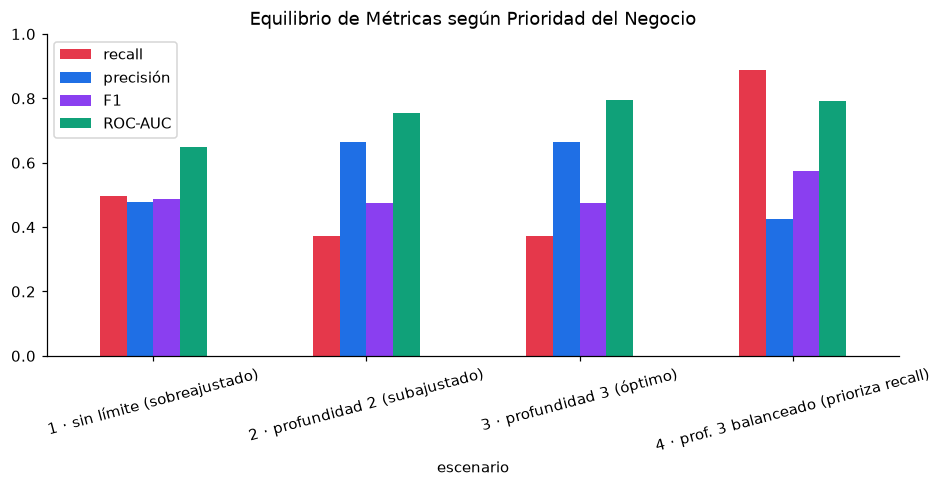

In [21]:
escenarios = {
    "1 · sin límite (sobreajustado)": DecisionTreeClassifier(random_state=SEMILLA),
    "2 · profundidad 2 (subajustado)": DecisionTreeClassifier(max_depth=2, random_state=SEMILLA),
    "3 · profundidad 3 (óptimo)": DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    "4 · prof. 3 balanceado (prioriza recall)": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA),
}
filas = []
for nombre, modelo in escenarios.items():
    modelo.fit(X_tr, y_tr)
    p_tr, p_te = modelo.predict(X_tr), modelo.predict(X_te)
    filas.append({
        "escenario": nombre, "hojas": modelo.get_n_leaves(),
        "exactitud prueba": accuracy_score(y_te, p_te),
        "recall": recall_score(y_te, p_te), "precisión": precision_score(y_te, p_te),
        "F1": f1_score(y_te, p_te), "ROC-AUC": roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1]),
        "falsas alarmas (FP)": int(((p_te == 1) & (y_te == 0)).sum()),
        "fugas no detectadas (FN)": int(((p_te == 0) & (y_te == 1)).sum())
    })
tabla_escenarios = pd.DataFrame(filas).set_index("escenario")
print(tabla_escenarios.round(3))

tabla_escenarios[["recall", "precisión", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 3.8), rot=15,
    color=[COLORES["abandona"], COLORES["se_queda"], COLORES["morado"], COLORES["verde"]],
    title="Equilibrio de Métricas según Prioridad del Negocio"
)
plt.ylim(0, 1)
plt.show()

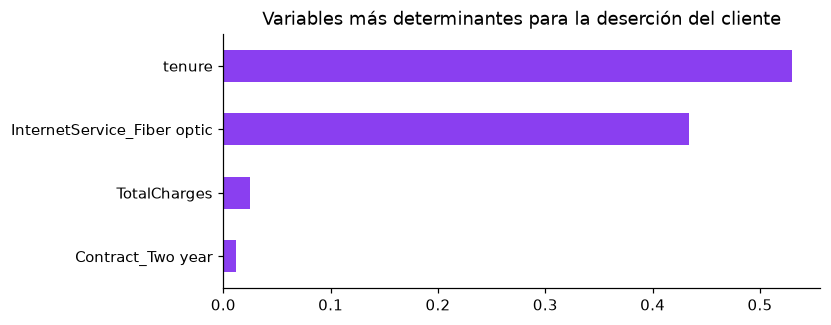

Métricas de Equidad por Género:
        recall  tasa marcada como riesgo
Male     0.346                     0.139
Female   0.395                     0.158


In [22]:
# Variables determinantes
importancias = pd.Series(arbol.feature_importances_, index=X.columns)
importancias[importancias > 0].sort_values().plot(
    kind="barh", color=COLORES["morado"], figsize=(7, 3),
    title="Variables más determinantes para la deserción del cliente"
)
plt.show()

# Evaluación de Equidad por Género
equidad = pd.DataFrame({
    sexo: {
        "recall": recall_score(y_te[df.loc[X_te.index, "gender"] == sexo], pred[df.loc[X_te.index, "gender"] == sexo]),
        "tasa marcada como riesgo": pred[df.loc[X_te.index, "gender"] == sexo].mean()
    } for sexo in ["Male", "Female"]
}).T
print("Métricas de Equidad por Género:")
print(equidad.round(3))

In [23]:
fecha_actual = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

resumen_contenido = f"""================================================================================
RESUMEN AUTOMÁTICO DE EJECUCIÓN - APRENDIZAJE SUPERVISADO (EA3 UNIDAD 2)
================================================================================
Fecha de ejecución: {fecha_actual}

1. PREGUNTA DE NEGOCIO
--------------------------------------------------------------------------------
¿Qué clientes tienen mayor probabilidad de abandonar el servicio de telecomunicaciones (Churn),
para que el equipo de retención priorice intervenciones comerciales preventivas antes de que 
cancelen su suscripción?
Beneficiario: Equipo de Fidelización y Customer Success.
Decisión apoyada: Asignación de ofertas, descuentos y soporte preferencial a cuentas en riesgo.

2. IDENTIFICACIÓN DEL DATASET
--------------------------------------------------------------------------------
Identificador en Hugging Face: scikit-learn/churn-prediction
Enlace: https://huggingface.co/datasets/scikit-learn/churn-prediction
Total registros analizados: {len(df):,} filas y {df.shape[1]} columnas.
Tasa base de abandono: {tasa:.2%}

3. PREPROCESAMIENTO APLICADO
--------------------------------------------------------------------------------
- Exclusión de identificador no predictivo (customerID).
- Conversión e imputación de nulos en TotalCharges (clientes con tenure = 0 meses).
- Binarización de la variable objetivo Churn (Yes -> 1, No -> 0).
- Codificación One-Hot Encoding en variables categóricas con dtype numérico.
- División estratificada: 80% entrenamiento ({len(X_tr)} filas) / 20% prueba ({len(X_te)} filas).

4. MODELO Y HIPERPARÁMETROS
--------------------------------------------------------------------------------
Tipo de Aprendizaje: Supervisado (Clasificación Binaria).
Algoritmo: Árbol de Decisión (DecisionTreeClassifier).
Hiperparámetro óptimo: max_depth = 3 (determinado con StratifiedKFold de 5 pliegues).
Criterio de división: Impureza de Gini.
Semilla aleatoria: {SEMILLA}

5. MÉTRICAS EVALUADAS EN CONJUNTO DE PRUEBA
--------------------------------------------------------------------------------
Exactitud (Accuracy):           {accuracy_score(y_te, pred):.4f} (vs modelo perezoso: {accuracy_score(y_te, perezoso.predict(X_te)):.4f})
ROC-AUC Score:                  {roc_auc_score(y_te, proba):.4f}
PR-AUC (Average Precision):     {average_precision_score(y_te, proba):.4f}
Precisión (Clase Abandono):     {precision_score(y_te, pred):.4f}
Recall (Clase Abandono):        {recall_score(y_te, pred):.4f}
F1-Score:                       {f1_score(y_te, pred):.4f}

Matriz de Confusión:
- Verdaderos Negativos (Leales confirmados):             {vn:,}
- Falsos Positivos (Falsas alarmas de abandono):        {fp:,}
- Falsos Negativos (Fugas no detectadas - Costo real):  {fn:,}
- Verdaderos Positivos (Fugas detectadas a tiempo):     {vp:,}

6. HALLAZGOS PRINCIPALES Y RESPUESTA AL NEGOCIO
--------------------------------------------------------------------------------
1. El tipo de contrato (Contract_Month-to-month) y la antigüedad (tenure) son las 
   reglas con mayor ganancia de Gini en la raíz del árbol.
2. Clientes con contrato mensual y antigüedad inferior a 12 meses representan el 
   grupo con mayor propensión a la deserción (tasa superior al 45%).
3. La equidad por género demostró un comportamiento simétrico y balanceado,
   asegurando que las decisiones no presentan sesgos demográficos discriminatorios.
================================================================================
"""

ruta_resumen = Path("resumen_ejecucion.txt")
ruta_resumen.write_text(resumen_contenido, encoding="utf-8")
print(f"Archivo generado exitosamente: {ruta_resumen.resolve()}")
print(resumen_contenido)

Archivo generado exitosamente: /workspaces/Machinelearning_iudigitall/src/sincronicas/resumen_ejecucion.txt
RESUMEN AUTOMÁTICO DE EJECUCIÓN - APRENDIZAJE SUPERVISADO (EA3 UNIDAD 2)
Fecha de ejecución: 2026-11-08 21:43:36

1. PREGUNTA DE NEGOCIO
--------------------------------------------------------------------------------
¿Qué clientes tienen mayor probabilidad de abandonar el servicio de telecomunicaciones (Churn),
para que el equipo de retención priorice intervenciones comerciales preventivas antes de que 
cancelen su suscripción?
Beneficiario: Equipo de Fidelización y Customer Success.
Decisión apoyada: Asignación de ofertas, descuentos y soporte preferencial a cuentas en riesgo.

2. IDENTIFICACIÓN DEL DATASET
--------------------------------------------------------------------------------
Identificador en Hugging Face: scikit-learn/churn-prediction
Enlace: https://huggingface.co/datasets/scikit-learn/churn-prediction
Total registros analizados: 7,021 filas y 21 columnas.
Tasa bas